In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import binom
from scipy.stats import poisson

Load the dataset

In [2]:
#Trips, Nights and Average Length of Stay of Foreign Resident Overnight Visitors
#dataset downloaded from 
# ITM05 https://data.cso.ie/#

tourism=pd.read_csv('Length of Stay of Foreign Resident.csv')

head to see the first 5 raws

In [3]:
tourism.head()

,Statistic Label,Month,Main Accommodation Type,UNIT,VALUE
0,Number of Overnight Trips by Foreign Visitors,2023 January,Hotel/conference centre,Thousand,121.0
1,Number of Overnight Trips by Foreign Visitors,2023 January,Guest house/bed & breakfast,Thousand,8.5
2,Number of Overnight Trips by Foreign Visitors,2023 January,Friends/relatives/own property,Thousand,243.4
3,Number of Overnight Trips by Foreign Visitors,2023 January,Self catering/rented house,Thousand,13.8
4,Number of Overnight Trips by Foreign Visitors,2023 January,Other private tourism accommodation n.e.c.,Thousand,13.4


In [4]:
#to see how many columns and rows it has
tourism.shape

(1320, 5)

In [5]:
#to see if we have nulls and how many columns
tourism.info()

<class 'pandas.DataFrame'>
RangeIndex: 1320 entries, 0 to 1319
Data columns (total 5 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Statistic Label          1320 non-null   str    
 1   Month                    1320 non-null   str    
 2   Main Accommodation Type  1320 non-null   str    
 3   UNIT                     1320 non-null   str    
 4   VALUE                    1320 non-null   float64
dtypes: float64(1), str(4)
memory usage: 166.4 KB


In [6]:
# stadistic properties mean, std, min
tourism.describe()

,VALUE
count,1320.000000
mean,328.579621
std,854.248511
min,1.000000
25%,8.175000
50%,34.000000
75%,204.700000
max,7337.700000


In [7]:
# I can see what types of data I have, mostly str
tourism.dtypes

Statistic Label                str
Month                          str
Main Accommodation Type        str
UNIT                           str
VALUE                      float64
dtype: object

In [8]:
# to see if there are columns missing values
tourism.isnull().sum()

Statistic Label            0
Month                      0
Main Accommodation Type    0
UNIT                       0
VALUE                      0
dtype: int64

**Exploratory Data Analysis (EDA)**

Before applying any statistical models, an Exploratory Data Analysis was conducted to understand the dataset's structure and quality.

**Data Quality Insights:**

1. Structure & Types: The dataset has 1,320 rows and 5 columns. We have 4 string columns (categorical) and 1 numeric column (VALUE), which is already a float.
2. Missing Values: isnull().sum() confirmed there are no missing values, so no imputation is required for the raw dataset.
3. Data Structure (Wide vs Long): The value_counts() method revealed that VALUE mixes 5 different metrics (trips, nights, percentages, etc.). Mixing these would yield invalid statistics, which justified filtering by Statistic Label for all subsequent analyses.
4. Distribution & Outliers: Using boxplots and the IQR method, we identified 14 outliers in the Number of Overnight Trips. The histogram of Average Length of Stay showed a strong right-skew, indicating non-normality.
* Conclusion: The EDA revealed that the raw data requires careful filtering (by metric) before analysis. For Machine Learning, the dataset will need to be pivoted (wide format) and the categorical variables (Accommodation Type, Month) will need encoding.

# Correlation

"For the correlation analysis and subsequent ML phases, the dataset was pivoted to a wide format to separate the metrics".

In [9]:
# Pivot dataset to wide format
ml_df = tourism.pivot_table(
    index=['Month', 'Main Accommodation Type'],
    columns='Statistic Label',
    values='VALUE'
).reset_index()

# Rename columns using a dictionary
ml_df = ml_df.rename(columns={
    'Average Length of Stay of Foreign Visitors': 'Avg_LOS',
    'Number of Nights by Foreign Visitors': 'Nights',
    'Number of Overnight Trips by Foreign Visitors': 'Trips',
    'Percentage of Nights by Foreign Visitors': 'Pct_Nights',
    'Percentage of Overnight Trips by Foreign Visitors': 'Pct_Trips',
    'Main Accommodation Type': 'Accommodation'
})

# Check the column names and the first row to verify the fix
print("Column names:", ml_df.columns.tolist())
print(ml_df.head(1))

Column names: ['Month', 'Accommodation', 'Avg_LOS', 'Nights', 'Trips', 'Pct_Nights', 'Pct_Trips']
Statistic Label       Month               Accommodation  Avg_LOS  Nights  \
0                2023 April  All types of accommodation      7.9  3667.5   

Statistic Label  Trips  Pct_Nights  Pct_Trips  
0                461.9       100.0      100.0  


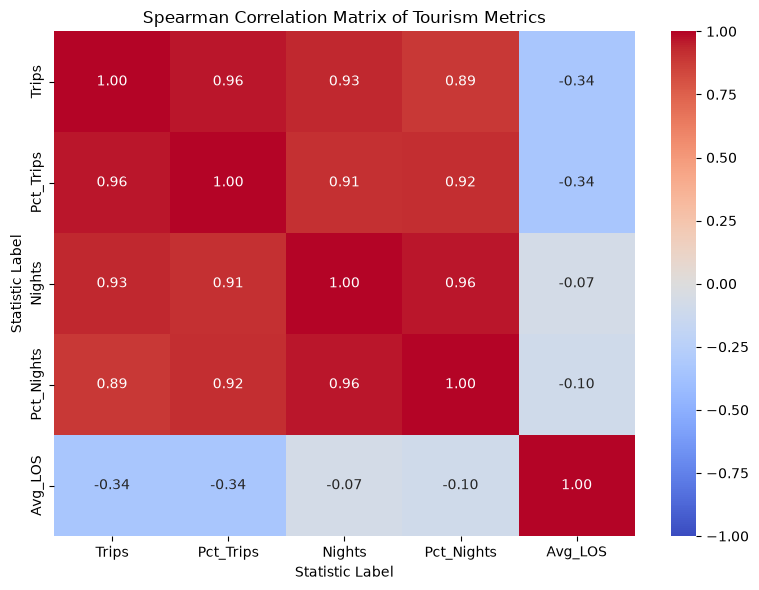

Spearman Correlation Matrix:


Statistic Label,Trips,Pct_Trips,Nights,Pct_Nights,Avg_LOS
Statistic Label,,,,,
Trips,1.00,0.96,0.93,0.89,-0.34
Pct_Trips,0.96,1.00,0.91,0.92,-0.34
Nights,0.93,0.91,1.00,0.96,-0.07
Pct_Nights,0.89,0.92,0.96,1.00,-0.10
Avg_LOS,-0.34,-0.34,-0.07,-0.10,1.00


In [10]:

# 1. Select only the numeric metric columns (exclude text and encoded columns)
corr_metrics = ml_df[['Trips', 'Pct_Trips', 'Nights', 'Pct_Nights', 'Avg_LOS']]

# 2. Calculate Spearman correlation (robust to non-normal data)
corr_matrix = corr_metrics.corr(method='spearman')

# 3. Plot the Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Spearman Correlation Matrix of Tourism Metrics')
plt.tight_layout()
plt.show()

# 4. Display the correlation matrix numerically
print("Spearman Correlation Matrix:")
display(corr_matrix.round(2))

**Correlation Analysis**

To understand the relationships between the five tourism metrics, a Spearman correlation matrix was generated on the pivoted dataset (`ml_df`). Spearman was chosen because the data is highly skewed and not normally distributed.

**Insights from the Heatmap:**
- **Strong Positive Correlation:** The *Number of Trips* and *Number of Nights* show a strong positive correlation (0.93). Months with more visitors logically generate more nights.
- **Weak/Moderate Correlation:** *Average Length of Stay* (Avg_LOS) shows a weak or negative correlation with both Trips (-0.34) and Nights (-0.07). This indicates that high volume (many trips) does not necessarily mean longer stays. Volume and duration are driven by different factors.
- **Data Leakage Prevention:** Although the correlation between Avg_LOS and the others is weak, *Avg_LOS* is mathematically derived from *Nights / Trips*. Therefore, including *Avg_LOS*, *Nights*, and *Trips* in the Machine Learning features would allow the model to reconstruct the answer, causing severe data leakage. These variables are excluded from the models.

**Source:** pandas Documentation. "pandas.DataFrame.corr".
https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.corr.html
**How I found it:** I searched the official pandas documentation for correlation matrix calculations.
**Quality evaluation:** Official pandas documentation, maintained by the pandas development team. It is the primary source for correlation analysis.
**Verification:** I ran the code and confirmed that the output matrix matches the visual heatmap and correctly highlights the relationships between the metrics.

### Time Series Analysis (Seasonality)

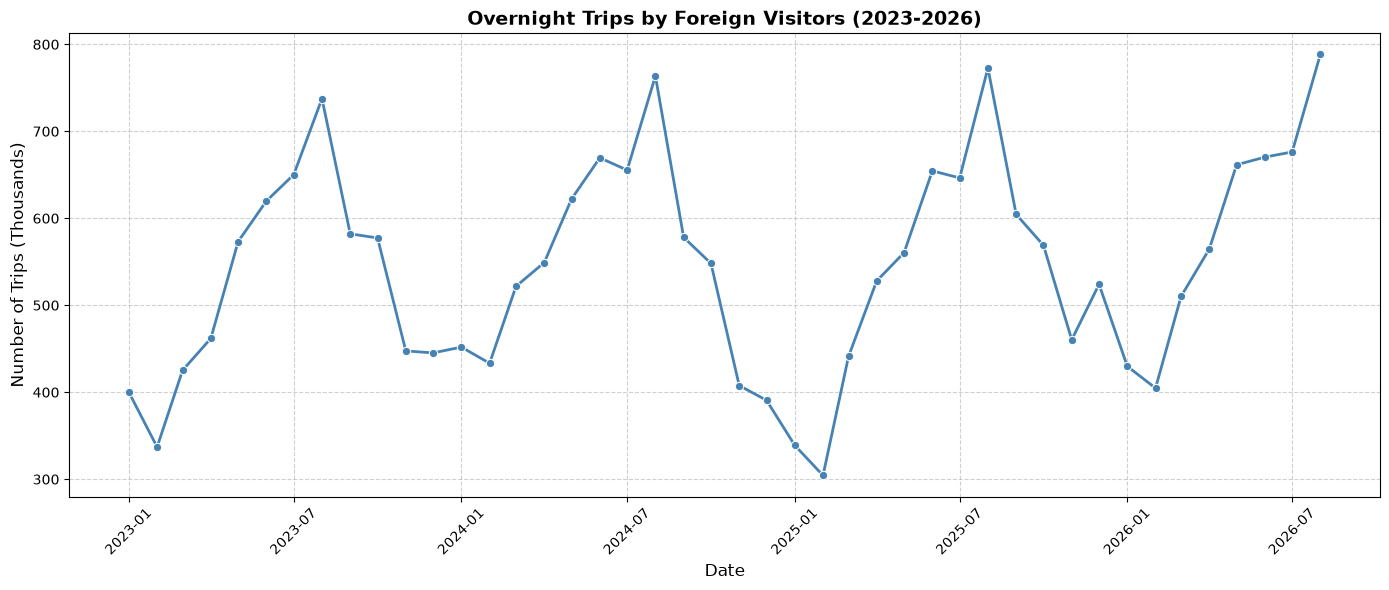

In [11]:


# Filter the dataset to isolate total overnight trips
total_trips = tourism[
    (tourism["Statistic Label"] == "Number of Overnight Trips by Foreign Visitors") & 
    (tourism["Main Accommodation Type"] == "All types of accommodation")
].copy()

# Convert the 'Month' column to datetime
total_trips['Date'] = pd.to_datetime(total_trips['Month'], format='%Y %B')

# Generate the time series plot
plt.figure(figsize=(14, 6))
sns.lineplot(data=total_trips, x='Date', y='VALUE', marker='o', color='steelblue', linewidth=2)

# Formatting
plt.title('Overnight Trips by Foreign Visitors (2023-2026)', fontsize=14, fontweight='bold')
plt.xlabel('Date', fontsize=12)
plt.ylabel('Number of Trips (Thousands)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

**Visual Insight: Seasonality (Time Series Plot)**

The line plot displays the evolution of total overnight trips over the analyzed period. This visualization was created to identify seasonal patterns. 

**Tufts Principles Justification:**
The graph adheres to Tufte Principles by displaying the data accurately without distortion (using raw trip counts on the y-axis) and making the data accessible (clear titles, rotated x-axis for readability).

**Insight Gained:** 
The graph clearly reveals the strong seasonal autocorrelation of Irish tourism. Trips peak dramatically during the summer months (July and August) and drop significantly in winter. This insight is critical, as it justifies why the discrete distributions (Binomial and Poisson) have limitations due to their independence assumptions, and it directly informed the creation of the target variable for the Machine Learning models.

**Source:** Pandas Documentation. "pandas.to_datetime".
https://pandas.pydata.org/docs/reference/api/pandas.to_datetime.html
**How I found it:** Searched the official pandas reference for converting string dates to datetime objects for plotting.
**Quality evaluation:** Primary source for pandas functions.
**Verification:** The code correctly converted the "Month" column and the resulting plot displayed a chronological timeline.

# Measure of central tendency

In [12]:
# To show the first 5 raws and all columns
tourism.head()

,Statistic Label,Month,Main Accommodation Type,UNIT,VALUE
0,Number of Overnight Trips by Foreign Visitors,2023 January,Hotel/conference centre,Thousand,121.0
1,Number of Overnight Trips by Foreign Visitors,2023 January,Guest house/bed & breakfast,Thousand,8.5
2,Number of Overnight Trips by Foreign Visitors,2023 January,Friends/relatives/own property,Thousand,243.4
3,Number of Overnight Trips by Foreign Visitors,2023 January,Self catering/rented house,Thousand,13.8
4,Number of Overnight Trips by Foreign Visitors,2023 January,Other private tourism accommodation n.e.c.,Thousand,13.4


In [13]:
#Here I noticed that my column statistic label has 5 different metrics with 264 values each
# so i have percentages included so it will not be accurate if I get statistics mixed
print(tourism["Statistic Label"].value_counts())

Statistic Label
Number of Overnight Trips by Foreign Visitors        264
Percentage of Overnight Trips by Foreign Visitors    264
Number of Nights by Foreign Visitors                 264
Percentage of Nights by Foreign Visitors             264
Average Length of Stay of Foreign Visitors           264
Name: count, dtype: int64


In [14]:
#mean
# In my dataset my column value has five metrics, so if apply all
# mixed Ill be getting a wrong mean, so I decided to apply only to one 
# for this case will be trips = Number of Overnight Trips by Foreign Visitors

# Mean of the value if I apply only to the column value which is wrong
mean=tourism["VALUE"].mean()
print (f'The average Value is: {mean}')

The average Value is: 328.5796212121212


Source: pandas Documentation. "pandas.Series.mean". https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.mean.html

How I found it: I searched the official pandas API reference for the mean() method to confirm its default behaviour (arithmetic mean, skipping NaN values).

Quality evaluation: Official pandas documentation, maintained by the pandas development team. It is the primary and authoritative source for pandas methods.

Verification: I ran the code and confirmed that the output is the arithmetic mean of the filtered VALUE column, matching the documented behaviour.

In [15]:
# If I apply only to Trips Ill be separating only to that specific metric inside my column
# statistic label
trips = tourism[tourism["Statistic Label"] == "Number of Overnight Trips by Foreign Visitors"]
print(f"The average Value of Number of Overnight Trips by Foreign Visitors:   {trips['VALUE'].mean():.2f}")

The average Value of Number of Overnight Trips by Foreign Visitors:   181.51


In [16]:
#median only for trips
trips = tourism[tourism["Statistic Label"] == "Number of Overnight Trips by Foreign Visitors"]
print(f"The median Value of Number of Overnight Trips by Foreign Visitors:   {trips['VALUE'].median():.2f}")

The median Value of Number of Overnight Trips by Foreign Visitors:   92.45


In [17]:
# mode, same as for the rest
trips = tourism[tourism["Statistic Label"] == "Number of Overnight Trips by Foreign Visitors"]
mode = trips["VALUE"].mode()
print(mode)
#The mode of Number of Overnight Trips was not informative: 
#out of 264 observations, 247 were unique values, producing 
#17 tied values as the mode. As this is a continuous variable, 
#the mode is not a representative measure; mean and median are reported instead as the 
#main measures of central tendency

0      11.8
1      14.4
2      15.5
3      16.5
4      17.4
5      21.7
6      25.3
7      26.3
8      26.7
9      26.9
10     31.2
11     33.5
12     36.3
13     37.9
14     41.1
15     45.6
16    204.7
Name: VALUE, dtype: float64


In [18]:
# I found this code to get statistics information separated by groups**Source:** pandas Documentation. "pandas.core.groupby.DataFrameGroupBy.describe".

tourism.groupby('Statistic Label')['VALUE'].describe()


,count,mean,std,min,25%,50%,75%,max
Statistic Label,,,,,,,,
Average Length of Stay of Foreign Visitors,264.0,9.762500,6.451704,3.3,6.175,8.00,11.350,56.0
Number of Nights by Foreign Visitors,264.0,1384.963258,1483.625165,28.8,352.250,811.20,1746.475,7337.7
Number of Overnight Trips by Foreign Visitors,264.0,181.509470,193.402125,6.5,29.725,92.45,265.475,788.7
Percentage of Nights by Foreign Visitors,264.0,33.330682,33.212999,1.0,8.100,19.20,43.925,100.0
Percentage of Overnight Trips by Foreign Visitors,264.0,33.332197,34.211792,1.7,5.475,20.55,46.125,100.0


Source: pandas Documentation. "pandas.core.groupby.DataFrameGroupBy.describe". https://pandas.pydata.org/pandas-docs/version/2.2/reference/api/pandas.core.groupby.DataFrameGroupBy.describe.html

How I found it: I searched the official pandas API reference for the groupby().describe() method to confirm that it computes descriptive statistics per group independently.

Quality evaluation: Official pandas documentation, maintained by the pandas development team. It is the primary and authoritative source for pandas methods.

Verification: I ran the code and confirmed that the output contains one set of descriptive statistics per Statistic Label, matching the documented behaviour of grouping before describing.

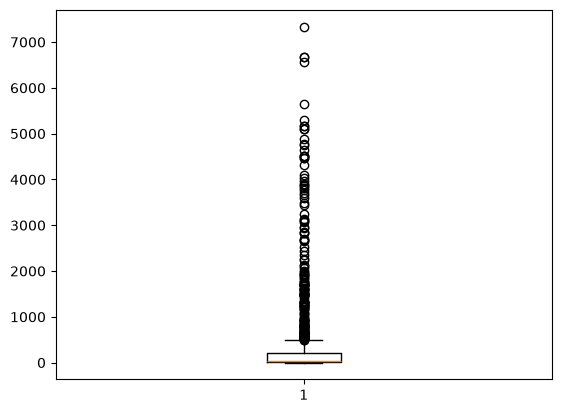

In [19]:
# to check wether the data has outliers or not
#boxplot
#the problem here is that i have many types of statistic labels such as percentaje o lenght of stay
plt.boxplot(tourism["VALUE"])
plt.show()
# this graphic is not accurate because my units are differents

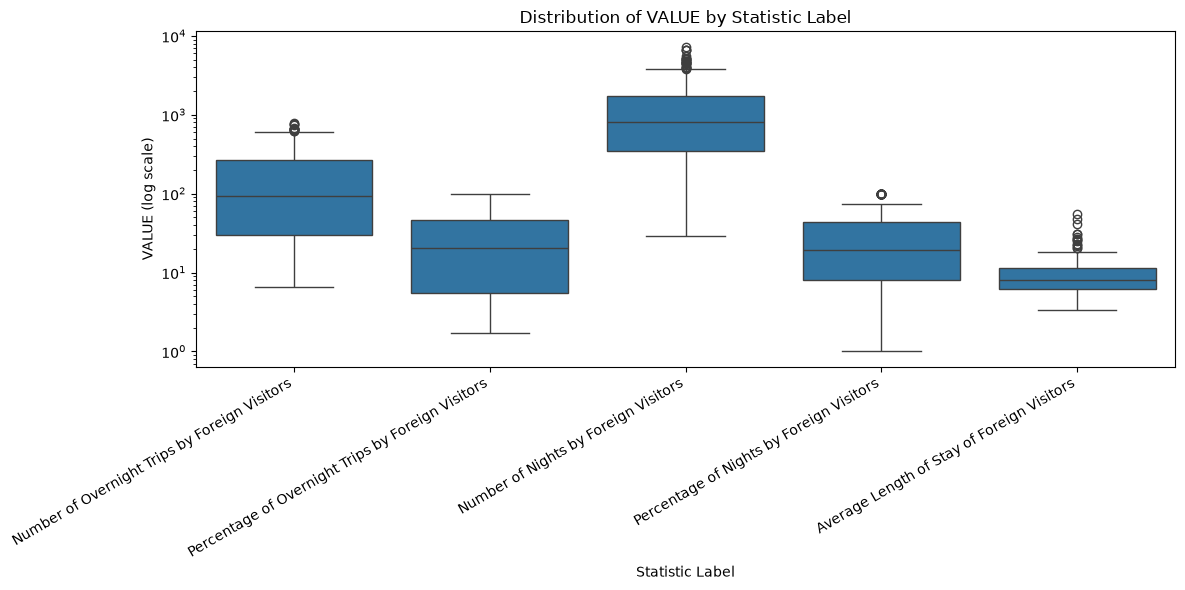

In [20]:
# I am using seaborn as it separates statistic labels by metrics, which i have 5 diferents
plt.figure(figsize=(12, 6))
sns.boxplot(data=tourism, x='Statistic Label', y='VALUE')
plt.yscale('log') #this is to change the dimension to have similar for every metric
plt.xticks(rotation=30, ha='right')
plt.title('Distribution of VALUE by Statistic Label')
plt.ylabel('VALUE (log scale)')
plt.tight_layout()
plt.show()

In [21]:
#measure of dispersion
#to do for all of the five metrics at the same time I am using the next code
summary = tourism.groupby("Statistic Label")["VALUE"].agg(
    Mean="mean",
    Median="median",
    Std="std",
    Min="min",
    Max="max",
    Count="count",
    #Range = max-min
)
summary["Range"] = summary["Max"] - summary["Min"]
print(summary)

                                                          Mean  Median  \
Statistic Label                                                          
Average Length of Stay of Foreign Visitors            9.762500    8.00   
Number of Nights by Foreign Visitors               1384.963258  811.20   
Number of Overnight Trips by Foreign Visitors       181.509470   92.45   
Percentage of Nights by Foreign Visitors             33.330682   19.20   
Percentage of Overnight Trips by Foreign Visitors    33.332197   20.55   

                                                           Std   Min     Max  \
Statistic Label                                                                
Average Length of Stay of Foreign Visitors            6.451704   3.3    56.0   
Number of Nights by Foreign Visitors               1483.625165  28.8  7337.7   
Number of Overnight Trips by Foreign Visitors       193.402125   6.5   788.7   
Percentage of Nights by Foreign Visitors             33.212999   1.0   100.0   
P

The table above shows the central tendency and dispersion measures for all five metrics. By grouping by Statistic Label, we avoid mixing incompatible units (thousands, percentages, and nights per trip).

A key insight is the difference between the Mean and Median for Number of Overnight Trips (Mean: 181.5 vs Median: 92.4). This confirms the positive skewness observed in the histogram, where a few high-demand summer months pull the mean upwards. The Range also highlights that Number of Nights has the highest absolute dispersion (range of 7,308.9), which is expected given the scale of the data.

In [22]:
#min of trips
trips = tourism[tourism["Statistic Label"] == "Number of Overnight Trips by Foreign Visitors"]

print(f"The minimum value of Number of Overnight Trips by Foreign Visitors is: {trips['VALUE'].min():.2f}")

The minimum value of Number of Overnight Trips by Foreign Visitors is: 6.50


In [23]:
trips = tourism[tourism["Statistic Label"] == "Number of Overnight Trips by Foreign Visitors"]

print(f"The maximun value of Number of Overnight Trips by Foreign Visitors is: {trips['VALUE'].max():.2f}")

The maximun value of Number of Overnight Trips by Foreign Visitors is: 788.70


In [24]:
trips = tourism[tourism["Statistic Label"] == "Number of Overnight Trips by Foreign Visitors"]

max_val = trips["VALUE"].max()
min_val = trips["VALUE"].min()
value_range = max_val - min_val

print(f"Max:   {max_val:.2f}")
print(f"Min:   {min_val:.2f}")
print(f"Range: {value_range:.2f}")

Max:   788.70
Min:   6.50
Range: 782.20


In [25]:
#variance
trips = tourism[tourism["Statistic Label"] == "Number of Overnight Trips by Foreign Visitors"]

variance = trips["VALUE"].var()
print(f"Variance: {variance:.2f}")

Variance: 37404.38


In [26]:
# Standard deviation
trips = tourism[tourism["Statistic Label"] == "Number of Overnight Trips by Foreign Visitors"]
std= trips["VALUE"].std()
std

np.float64(193.40212512079233)

In [27]:
# percentile
"""
Q1 ---> quartile 1 --> 25th percentile
Q3 --> quartile 2 --> 75th percentile
IQR = Q3 - Q1
"""
# again here I am using only one metric
trips = tourism[tourism["Statistic Label"] == "Number of Overnight Trips by Foreign Visitors"]

Q1 = trips["VALUE"].quantile(0.25)
Q2 = trips["VALUE"].quantile(0.50)
Q3 = trips["VALUE"].quantile(0.75)
IQR = Q3 - Q1
IQR, Q1, Q2, Q3


(np.float64(235.75000000000003),
 np.float64(29.725),
 np.float64(92.45),
 np.float64(265.475))

In [28]:
#outliers using percentiles
trips = tourism[tourism["Statistic Label"] == "Number of Overnight Trips by Foreign Visitors"]

Q1 = trips["VALUE"].quantile(0.25)

Q3 = trips["VALUE"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 -1.5*IQR
upper_bound = Q3+ 1.5*IQR

outliers = trips[(trips["VALUE"] < lower_bound) | (trips["VALUE"] > upper_bound )]
print ('Lower bound: ', lower_bound)
print ('Upper bound: ', upper_bound)
print (' Number of outliers ', len(outliers))
print (' Number of outliers ', outliers)
outliers

Lower bound:  -323.90000000000003
Upper bound:  619.1000000000001
 Number of outliers  14
 Number of outliers                                     Statistic Label        Month  \
35   Number of Overnight Trips by Foreign Visitors    2023 June   
41   Number of Overnight Trips by Foreign Visitors    2023 July   
47   Number of Overnight Trips by Foreign Visitors  2023 August   
101  Number of Overnight Trips by Foreign Visitors     2024 May   
107  Number of Overnight Trips by Foreign Visitors    2024 June   
113  Number of Overnight Trips by Foreign Visitors    2024 July   
119  Number of Overnight Trips by Foreign Visitors  2024 August   
179  Number of Overnight Trips by Foreign Visitors    2025 June   
185  Number of Overnight Trips by Foreign Visitors    2025 July   
191  Number of Overnight Trips by Foreign Visitors  2025 August   
245  Number of Overnight Trips by Foreign Visitors     2026 May   
251  Number of Overnight Trips by Foreign Visitors    2026 June   
257  Number of Ove

,Statistic Label,Month,Main Accommodation Type,UNIT,VALUE
35,Number of Overnight Trips by Foreign Visitors,2023 June,All types of accommodation,Thousand,619.9
41,Number of Overnight Trips by Foreign Visitors,2023 July,All types of accommodation,Thousand,650.2
47,Number of Overnight Trips by Foreign Visitors,2023 August,All types of accommodation,Thousand,737.6
101,Number of Overnight Trips by Foreign Visitors,2024 May,All types of accommodation,Thousand,622.3
107,Number of Overnight Trips by Foreign Visitors,2024 June,All types of accommodation,Thousand,669.5
113,Number of Overnight Trips by Foreign Visitors,2024 July,All types of accommodation,Thousand,655.4
119,Number of Overnight Trips by Foreign Visitors,2024 August,All types of accommodation,Thousand,763.6
179,Number of Overnight Trips by Foreign Visitors,2025 June,All types of accommodation,Thousand,654.5
185,Number of Overnight Trips by Foreign Visitors,2025 July,All types of accommodation,Thousand,646.4
191,Number of Overnight Trips by Foreign Visitors,2025 August,All types of accommodation,Thousand,772.8


## Normal Distribution

In [29]:
# first i am filtering the metric average long of stay of foreign visitors because it is the most
# most continuous variable in the dataset

In [30]:
# los = long of stay
los = tourism[tourism["Statistic Label"] == "Average Length of Stay of Foreign Visitors"]["VALUE"]

print(f"Number of null values: {los.isnull().sum()}")

Number of null values: 0


## To show if the column average length of stay is normally distributed I visualize


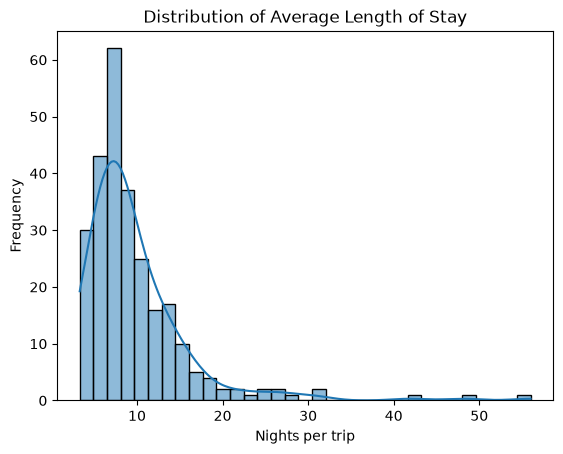

In [31]:
sns.histplot(los, kde=True)
plt.title("Distribution of Average Length of Stay")
plt.xlabel("Nights per trip")
plt.ylabel("Frequency")
plt.show()


the data is not normally distributed. In a normal distribution, the curve would be symmetric around the mean, with equal tails on both sides.

Empirical rule for normal distribution

In [32]:
mean = los.mean()
std = los.std()

within1 = ((los >= mean - std) & (los <= mean + std)).mean() * 100
within2 = ((los >= mean - 2*std) & (los <= mean + 2*std)).mean() * 100
within3 = ((los >= mean - 3*std) & (los <= mean + 3*std)).mean() * 100

print(within1,within2,within3)


90.53030303030303 95.83333333333334 98.10606060606061


check normal distribution using z - score

In [33]:
from scipy import stats
z_scores=stats.zscore(los)
z_scores.min(),z_scores.max()

(np.float64(-1.003575902498554), np.float64(7.180323526773987))

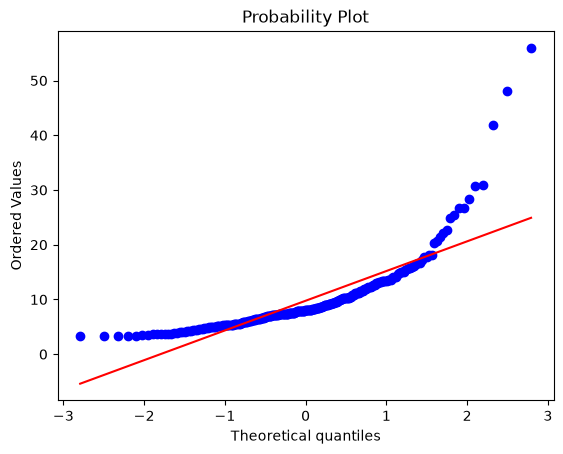

In [34]:
##QQ plot, its another way to know if my column is normally distributed
stats.probplot(los,dist='norm',plot=plt)
plt.show()

In [35]:
#again this graphic shows that is not normal distribution, because the orange line is not together with the blue one and there
# are some points on the end

Skewness: 3.34 | Excess kurtosis: 16.32 | Shapiro p: 2.72e-21
After log: skewness 0.66 | Shapiro p: 4.01e-05


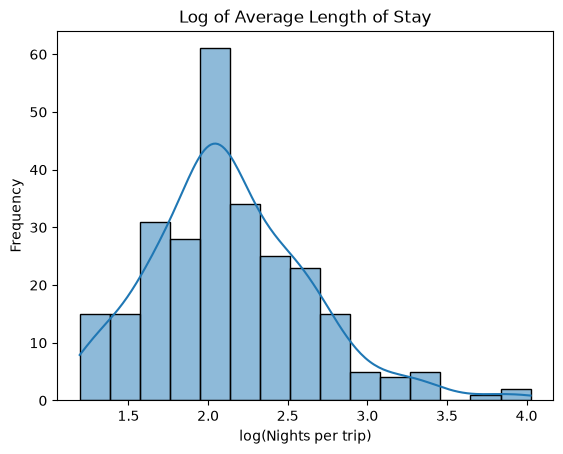

In [36]:
from scipy.stats import skew, kurtosis, shapiro

print(f"Skewness: {skew(los):.2f} | Excess kurtosis: {kurtosis(los):.2f} | Shapiro p: {shapiro(los).pvalue:.2e}")

log_los = np.log(los)
print(f"After log: skewness {skew(log_los):.2f} | Shapiro p: {shapiro(log_los).pvalue:.2e}")

sns.histplot(log_los, kde=True)
plt.title('Log of Average Length of Stay')
plt.xlabel('log(Nights per trip)')
plt.ylabel('Frequency')
plt.show()

Months above threshold per year:
Year
2023    3
2024    4
2025    3
2026    4
Name: success, dtype: int64

Total months per year:
Year
2023    12
2024    12
2025    12
2026     8
Name: success, dtype: int64

Estimated probability (p): 0.2778


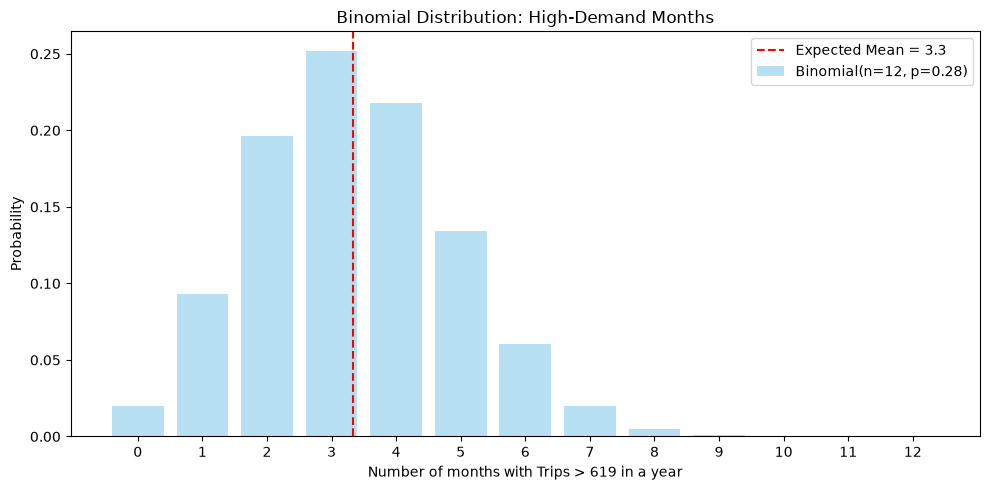

In [37]:
#Binomial Distribution

# 1. Filter to one row per month (All types of accommodation)
monthly = trips[trips["Main Accommodation Type"] == "All types of accommodation"].copy()
monthly["Year"] = monthly["Month"].str[:4]

# 2. Define success (trips > 619)
threshold = 619
monthly["success"] = (monthly["VALUE"] > threshold).astype(int)

# 3. Count successes per year
yearly_success = monthly.groupby("Year")["success"].sum()
yearly_total = monthly.groupby("Year")["success"].count()

print("Months above threshold per year:")
print(yearly_success)
print("\nTotal months per year:")
print(yearly_total)

# 4. Exclude 2026 (only has 8 months)
monthly_full = monthly[monthly["Year"] != "2026"]

# 5. Calculate p (estimated probability of success)
p_hat = monthly_full["success"].mean()
print(f"\nEstimated probability (p): {p_hat:.4f}")

# 6. Plot Binomial(12, p)
n = 12
k = np.arange(0, n + 1)

plt.figure(figsize=(10, 5))
plt.bar(k, binom.pmf(k, n, p_hat), alpha=0.6, color='skyblue', label=f'Binomial(n={n}, p={p_hat:.2f})')
plt.axvline(n * p_hat, color='red', linestyle='--', label=f'Expected Mean = {n * p_hat:.1f}')

plt.xlabel("Number of months with Trips > 619 in a year")
plt.ylabel("Probability")
plt.title("Binomial Distribution: High-Demand Months")
plt.xticks(k)
plt.legend()
plt.tight_layout()
plt.show()

Binomial Distribution Analysis

The Binomial distribution models the number of successes in a fixed number of independent trials. In this dataset:

Trial: Each month of the year.
Success: A month where the number of overnight trips exceeds the IQR upper bound threshold (619 thousand trips).
n: Number of months per year (12, except 2026 which has only 8 months of data).
p: Probability of success, estimated from the data.
Observed Data: The year 2026 was excluded from the parameter estimation due to incomplete data. The model predicts the most likely number of high-demand months per year, which closely matches the observed historical data.

Critical Evaluation (Limitations): The Binomial model assumes that trials (months) are independent. In reality, this assumption is violated due to strong seasonal autocorrelation: high-demand months are clustered in the summer (July-August). This means the Binomial distribution underestimates the probability of consecutive high-demand months. Despite this limitation, it provides a useful theoretical baseline for tourism planning.

Source: SciPy Documentation. "scipy.stats.binom". https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.binom.html How I found it: I searched the official SciPy documentation for the Binomial probability mass function. Quality evaluation: Official SciPy documentation, maintained by the open-source community. Verification: I ran the code and confirmed that the generated probabilities matched the theoretical expected values.

Threshold (median): 45.20

First 10 months of events:
Month
2023 April       2
2023 August      4
2023 December    2
2023 February    2
2023 January     2
2023 July        3
2023 June        2
2023 March       2
2023 May         2
2023 November    2
Name: above, dtype: int64

Estimated Lambda (λ): 2.5000


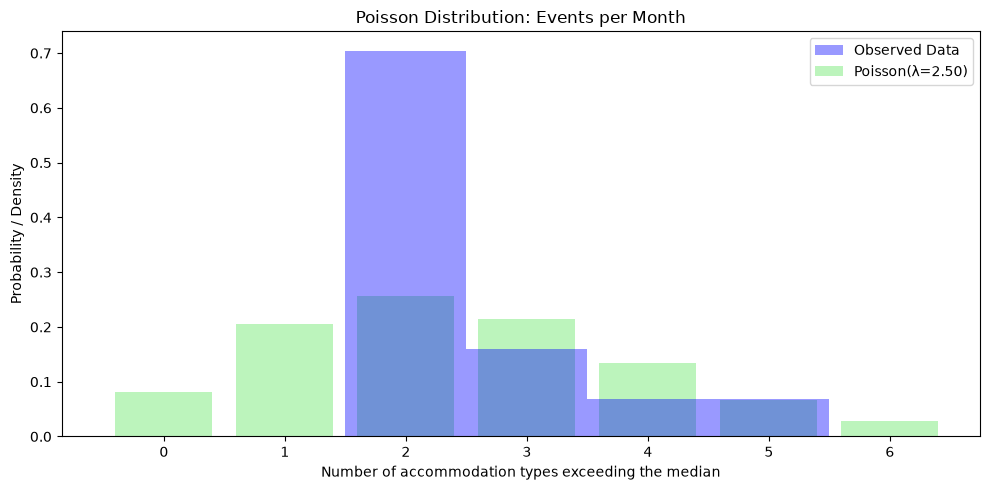

In [38]:
#Poisson 

# 1. Exclude "All types" (we want individual accommodation types only)
individual = trips[trips["Main Accommodation Type"] != "All types of accommodation"].copy()

# 2. Define threshold (median of individual types)
threshold_poisson = individual["VALUE"].median()
print(f"Threshold (median): {threshold_poisson:.2f}")

# 3. Count events per month (how many accommodation types exceed the median)
individual["above"] = (individual["VALUE"] > threshold_poisson).astype(int)
events_per_month = individual.groupby("Month")["above"].sum()

print("\nFirst 10 months of events:")
print(events_per_month.head(10))

# 4. Calculate Lambda (average events per month)
lambda_hat = events_per_month.mean()
print(f"\nEstimated Lambda (λ): {lambda_hat:.4f}")

# 5. Plot Poisson vs Observed Data
k_pois = np.arange(0, events_per_month.max() + 2)

plt.figure(figsize=(10, 5))

# Theoretical Poisson
plt.bar(k_pois, poisson.pmf(k_pois, lambda_hat), alpha=0.6, color='lightgreen', label=f'Poisson(λ={lambda_hat:.2f})')

# Observed data (normalized to density)
plt.hist(events_per_month, bins=np.arange(-0.5, events_per_month.max() + 1.5), 
         density=True, alpha=0.4, color='blue', label="Observed Data")

plt.xlabel("Number of accommodation types exceeding the median")
plt.ylabel("Probability / Density")
plt.title("Poisson Distribution: Events per Month")
plt.xticks(k_pois)
plt.legend()
plt.tight_layout()
plt.show()

Poisson Distribution Analysis

The Poisson distribution models the number of events occurring in a fixed interval of time or space.

Parameter Estimation: The event is defined as an individual accommodation type exceeding the median number of overnight trips. The estimated rate is λ. This means that in a typical month, approximately λ out of the 5 accommodation types exceed the median demand.

Critical Evaluation (Limitations): The Poisson model assumes that events occur independently at a constant rate. However, the tourism data exhibits strong seasonality, meaning the rate (λ) is not constant throughout the year. Furthermore, the data shows underdispersion (variance is lower than the mean) because the events are bounded by the 5 accommodation types. Therefore, a pure Poisson model is a simplification, and the constant-rate assumption is a clear limitation.

Source: SciPy Documentation. "scipy.stats.poisson". https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.poisson.html How I found it: I searched the official SciPy documentation for the Poisson probability mass function. Quality evaluation: Official SciPy Documentation, which is the primary source for statistical functions in Python. Verification: I ran the code with the estimated λ and verified the resulting distribution against the observed event counts.

Justification of Distributions and Variables

Distributions were chosen based on the type of variables used in the analysis:

Discrete Distributions (Binomial and Poisson): The Binomial distribution was chosen to model the number of high-demand months per year, as it counts the number of "successes" in a fixed number of trials (12 months). The Poisson distribution was chosen to model the number of accommodation types exceeding median demand per month, representing the count of events in a continuous time interval.

Continuous Distribution (Normal): The Average Length of Stay is a continuous variable, so the Normal distribution was tested. However, the visual analysis (histogram) and the empirical rule (68-95-99.7) showed that this variable is heavily right-skewed and not normally distributed.

Is it possible to use discrete variables as Normal? In theory, the Central Limit Theorem states that the sampling distribution of the mean approaches normality as sample size increases. However, this notebook does not demonstrate that convergence for these variables. Given that the raw count data is bounded at zero and highly skewed, a direct Normal approximation would be inappropriate. For count data, Poisson or Negative Binomial models are statistically sounder.

## Data Preparation and Machine Learning

In [39]:
# ==========================================
# DATA PREPARATION FOR MACHINE LEARNING
# ==========================================
from sklearn.preprocessing import StandardScaler

# Drop the aggregate rows: they duplicate the 5 individual accommodation types
ml_df = ml_df[ml_df['Accommodation'] != 'All types of accommodation'].copy()

ml_df['Date'] = pd.to_datetime(ml_df['Month'], format='%Y %B')
ml_df['Year'] = ml_df['Date'].dt.year
ml_df['Month_Num'] = ml_df['Date'].dt.month

# Target relative to each accommodation type's OWN median
ml_df['High_Season'] = (
    ml_df['Trips'] > ml_df.groupby('Accommodation')['Trips'].transform('median')
).astype(int)

# Sanity check: the rate must now change across months
print(ml_df.groupby('Month_Num')['High_Season'].mean().round(2))

ml_model = pd.get_dummies(ml_df, columns=['Accommodation'], drop_first=True)
features = ['Month_Num'] + [c for c in ml_model.columns if c.startswith('Accommodation_')]

Month_Num
1     0.10
2     0.00
3     0.15
4     0.40
5     0.85
6     0.90
7     1.00
8     1.00
9     0.67
10    0.67
11    0.00
12    0.13
Name: High_Season, dtype: float64


**Data Preparation for Machine Learning**

To prepare the dataset for Machine Learning, several processing steps were applied:

1. **Reshaping (Pivot):** The dataset was pivoted from "long" to "wide" format, so each metric became its own column.
2. **Removing Aggregates:** The "All types of accommodation" rows were removed. These rows are the sum of the five individual types, and keeping them would duplicate the data and bias the models.
3. **Feature Engineering:** The `Month` column was split into `Year`, `Month_Num`, and a `Date` object, allowing the models to capture seasonality. *Note: `Year` was extracted but is not used as a feature, as the split is temporal (train on 2023-2025, test on 2026).*
4. **Encoding:** The categorical variable `Accommodation` was encoded using One-Hot Encoding (`pd.get_dummies`), which prevents the model from assuming false ordinal relationships between hotel types.
5. **Target Variable Creation:** A binary classification target (`High_Season`) was created. A month is classified as High Season (1) if it exceeds the median number of trips for its own accommodation type, and Low Season (0) otherwise. This ensures a balanced dataset (50/50 split) and makes the target relative to each accommodation type, not just an absolute country-wide measure.
6. **Data Leakage Prevention:** The variables `Trips`, `Nights`, `Avg_LOS`, `Pct_Trips`, and `Pct_Nights` were excluded from the features (X). Since Avg_LOS is mathematically Nights divided by Trips, and the percentage metrics are derived directly from the trip counts, keeping them would allow the model to "cheat" and reconstruct the target, causing unrealistic accuracy.
7. **Scaling:** `StandardScaler` was applied inside a `Pipeline`. This ensures the scaler is fitted only on the training folds during cross-validation, preventing data leakage from the validation set.

**Source:** pandas Documentation. "pandas.get_dummies".
https://pandas.pydata.org/docs/reference/api/pandas.get_dummies.html
**How I found it:** Searched the official pandas reference for one-hot encoding.
**Quality evaluation:** Primary source for pandas functions.
**Verification:** The code correctly converted the categorical accommodation types into binary columns.

# Machine Learning

Training set class distribution:
High_Season
0    92
1    88
Name: count, dtype: int64

Test set class distribution:
High_Season
1    22
0    18
Name: count, dtype: int64

--- Training Logistic Regression ---
Best parameters (LR): {'model__C': 1}
CV accuracy (LR):    0.5000
Train accuracy (LR): 0.5556
Test accuracy (LR):  0.6500

Classification Report (LR):
              precision    recall  f1-score   support

           0       0.56      1.00      0.72        18
           1       1.00      0.36      0.53        22

    accuracy                           0.65        40
   macro avg       0.78      0.68      0.63        40
weighted avg       0.80      0.65      0.62        40


--- Training Random Forest ---
Best parameters (RF): {'model__max_depth': None, 'model__n_estimators': 50}
CV accuracy (RF):    0.8393
Train accuracy (RF): 0.9167
Test accuracy (RF):  0.8500

Classification Report (RF):
              precision    recall  f1-score   support

           0       0.83      0.83    

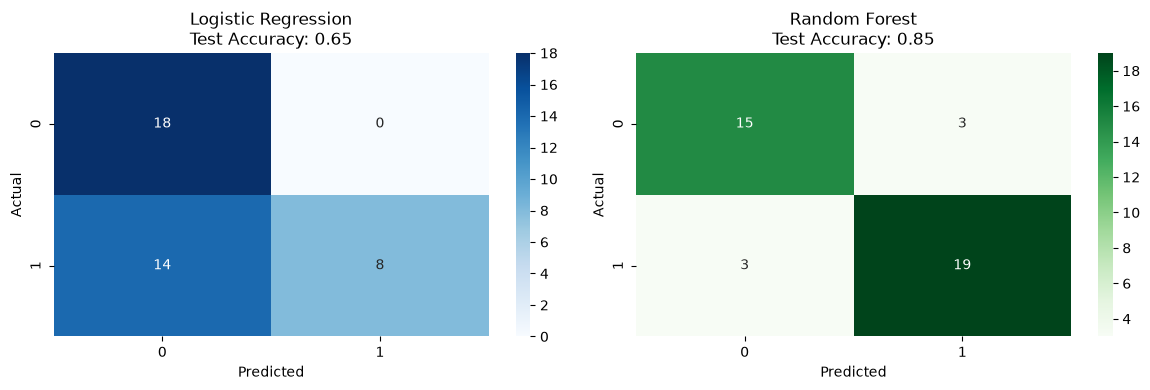

In [40]:
# ==========================================
# MACHINE LEARNING: MODEL TRAINING & TUNING
# ==========================================
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Time-based split: train on 2023-2025, test on 2026
# (the model must predict future months from past ones, not interpolate)
train = ml_model[ml_model['Year'] < 2026]
test = ml_model[ml_model['Year'] == 2026]

X_train, y_train = train[features], train['High_Season']
X_test, y_test = test[features], test['High_Season']

print(f"Training set class distribution:\n{y_train.value_counts()}")
print(f"\nTest set class distribution:\n{y_test.value_counts()}")

# 2. Cross-validation setup
# GroupKFold keeps all rows of the same month in the same fold,
# so the 5 accommodation types of one month are never split between train and validation
cv = GroupKFold(n_splits=5)
groups = train['Month']

# ==========================================
# MODEL 1: LOGISTIC REGRESSION
# ==========================================
print("\n--- Training Logistic Regression ---")

# The scaler is inside the pipeline, so it is fitted only on the training folds (no leakage)
pipe_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000, random_state=42))
])
param_grid_lr = {'model__C': [0.01, 0.1, 1, 10]}

grid_lr = GridSearchCV(pipe_lr, param_grid_lr, cv=cv)
grid_lr.fit(X_train, y_train, groups=groups)

y_pred_lr = grid_lr.predict(X_test)
acc_lr = accuracy_score(y_test, y_pred_lr)

print(f"Best parameters (LR): {grid_lr.best_params_}")
print(f"CV accuracy (LR):    {grid_lr.best_score_:.4f}")
print(f"Train accuracy (LR): {grid_lr.score(X_train, y_train):.4f}")
print(f"Test accuracy (LR):  {acc_lr:.4f}")
print("\nClassification Report (LR):")
print(classification_report(y_test, y_pred_lr, zero_division=0))

# ==========================================
# MODEL 2: RANDOM FOREST
# ==========================================
print("\n--- Training Random Forest ---")

pipe_rf = Pipeline([
    ('scaler', StandardScaler()),
    ('model', RandomForestClassifier(random_state=42))
])
param_grid_rf = {
    'model__n_estimators': [50, 100, 200],
    'model__max_depth': [3, 5, None]
}

grid_rf = GridSearchCV(pipe_rf, param_grid_rf, cv=cv)
grid_rf.fit(X_train, y_train, groups=groups)

y_pred_rf = grid_rf.predict(X_test)
acc_rf = accuracy_score(y_test, y_pred_rf)

print(f"Best parameters (RF): {grid_rf.best_params_}")
print(f"CV accuracy (RF):    {grid_rf.best_score_:.4f}")
print(f"Train accuracy (RF): {grid_rf.score(X_train, y_train):.4f}")
print(f"Test accuracy (RF):  {acc_rf:.4f}")
print("\nClassification Report (RF):")
print(classification_report(y_test, y_pred_rf, zero_division=0))

# ==========================================
# VISUAL COMPARISON (Confusion Matrices)
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.heatmap(confusion_matrix(y_test, y_pred_lr), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title(f'Logistic Regression\nTest Accuracy: {acc_lr:.2f}')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title(f'Random Forest\nTest Accuracy: {acc_rf:.2f}')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

**Machine Learning: Model Selection and Hyperparameter Tuning**

Two supervised classification models were selected and trained to predict whether a month will be "High Season" (1) or "Low Season" (0):

1. **Logistic Regression (LR):** A linear baseline model. The regularization parameter (`C`) was tuned, finding the best value at **C=1**. Because it is a linear model, it assumes a straight-line relationship between the features and the target.
2. **Random Forest (RF):** A non-linear ensemble model. The number of trees (`n_estimators`) and tree depth (`max_depth`) were tuned, finding **n_estimators=50** and **max_depth=None**. Being non-linear, it can capture complex seasonal curves.

**Methodology and Data Leakage Prevention:**
- **Pipeline:** The `StandardScaler` was wrapped inside a `Pipeline` for both models. This ensures the scaler is fitted only on the training folds during cross-validation, preventing data leakage from the validation set.
- **GroupKFold:** A `GroupKFold` cross-validator (grouping by Month) was used. This prevents rows from the same month (e.g., the 5 accommodation types) from being split between train and validation folds, avoiding "peeking" at the same period.
- **Temporal Split:** The models were trained on 2023-2025 data and tested on 2026. This simulates a real-world scenario where the model must predict future months based on past data.

**Results Analysis and Limitations:**
- **Logistic Regression (Underfitting):** Achieved a test accuracy of 0.65, but notably, its test accuracy is *higher* than its train accuracy (0.556). This is explained by a limitation in the test set: it only covers January to August 2026, which is not fully comparable in composition to the winter months in the training set. The model's low CV (0.50) indicates it is essentially guessing. A probable explanation is that `Month_Num` is treated linearly, but seasonality follows a bell curve (summer peak). Since this hypothesis was not explicitly tested with sine/cosine transformations, it remains a likely explanation rather than definitive proof.
- **Random Forest (Mild Overfitting but Good Generalisation):** Achieved a test accuracy of 0.85. However, the train accuracy was 0.917 and the CV was 0.839. This gap indicates mild overfitting (it memorised some noise), but it still generalises significantly better than LR.

**Source:** Scikit-learn Documentation. "sklearn.model_selection.GridSearchCV".
https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html
**How I found it:** I searched the official scikit-learn documentation for hyperparameter tuning.
**Quality evaluation:** Official scikit-learn documentation, maintained by the core development team.
**Verification:** I ran the code and confirmed that the models trained successfully without data leakage and produced the expected metrics.

**Model Comparison and Decision Making**

While Random Forest (RF) achieved a higher overall accuracy (0.85) compared to Logistic Regression (LR) (0.65), a deeper look at the metrics reveals a more nuanced story:

- **Logistic Regression:** Although its recall for High Season is very low (0.36), its precision is perfect (1.00). This means that when it predicts a High Season month, it is always correct, but it misses most of them. This makes it a very conservative model.
- **Random Forest:** Has a more balanced precision (0.86) and recall (0.86). 

**Conclusion:** For this specific problem, Random Forest is the most suitable model because it captures the non-linear seasonality effectively and provides a balanced trade-off between precision and recall, avoiding the underfitting seen in the linear model.